In [ ]:
# 5. Automobile Sales and Performance AnalysisBusiness situation:

# You are working as a Data Analyst in an automobile manufacturing company. Management wants to analyze vehicle sales, brand performance, customer preferences and regional demand.

# Dataset requirements:
# - Vehicle_ID
# - Brand
# - Model
# - Vehicle_Type
# - Fuel_Type
# - Manufacturing_Year
# - Selling_Price
# - Units_Sold
# - Mileage
# - Customer_Rating
# - Region
# - Sales_Date
# Business questions:
# 1. Which automobile brand generates the highest revenue?
# 2. Which fuel type is most popular?
# 3. Which vehicle type has maximum demand?
# 4. Which region generates the highest sales?
# 5. How do vehicle sales change monthly?
# 6. Is vehicle price related to customer ratings?
# 7. How do petrol, diesel and electric vehicle sales compare?
# 8. Which models have the highest average selling price?
# Expected Matplotlib plots:
# - Multiple line plots – Brand-wise sales trends
# - Grouped bar – Fuel type comparison
# - Pie chart – Vehicle category distribution
# - Histogram – Selling price distribution
# - Scatter plot – Price vs rating
# - Box plot – Brand-wise prices
# - Twin Y-axis – Units sold vs revenue
# - Heatmap – Vehicle performance correlation
# - Dashboard – Automobile analytics

In [6]:

pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

In [4]:
# . Create Automobile Dataset
data = {
    'Vehicle_ID': range(1, 16),

    'Brand': [
        'Tata', 'Mahindra', 'Hyundai', 'Maruti', 'Tata',
        'Toyota', 'Mahindra', 'Hyundai', 'Maruti', 'Tata',
        'Toyota', 'Mahindra', 'Hyundai', 'Maruti', 'Tata'
    ],
    'Model': [
        'Nexon', 'Scorpio', 'Creta', 'Swift', 'Punch',
        'Fortuner', 'XUV700', 'Venue', 'Baleno', 'Harrier',
        'Innova', 'Thar', 'i20', 'Brezza', 'Safari'
    ],
    'Vehicle_Type': [
        'SUV', 'SUV', 'SUV', 'Hatchback', 'SUV',
        'SUV', 'SUV', 'SUV', 'Hatchback', 'SUV',
        'MUV', 'SUV', 'Hatchback', 'SUV', 'SUV'
    ],
    'Fuel_Type': [
        'Petrol', 'Diesel', 'Diesel', 'Petrol', 'Electric',
        'Diesel', 'Diesel', 'Petrol', 'Petrol', 'Diesel',
        'Diesel', 'Petrol', 'Petrol', 'Petrol', 'Diesel'
    ],
    'Manufacturing_Year': [
        2022, 2023, 2022, 2021, 2024,
        2023, 2024, 2022, 2021, 2023,
        2022, 2024, 2021, 2023, 2024
    ],
    'Selling_Price': [
        12, 18, 16, 7, 9,
        40, 25, 10, 8, 22,
        25, 16, 9, 11, 23
    ],
    'Units_Sold': [
        120, 90, 100, 150, 110,
        40, 70, 130, 140, 60,
        50, 80, 125, 115, 55
    ],
    'Mileage': [
        17, 15, 18, 22, 25,
        12, 15, 20, 23, 16,
        14, 15, 20, 19, 14
    ],
    'Customer_Rating': [
        4.5, 4.2, 4.4, 4.3, 4.6,
        4.8, 4.5, 4.1, 4.2, 4.4,
        4.6, 4.5, 4.0, 4.3, 4.7
    ],
    'Region': [
        'West', 'North', 'South', 'West', 'East',
        'North', 'West', 'South', 'East', 'West',
        'South', 'North', 'East', 'West', 'South'
    ],
    'Sales_Date': pd.date_range(
        start='2025-01-01',
        periods=15,
        freq='MS'
    )
}
df = pd.DataFrame(data)
print(df)

    Vehicle_ID     Brand     Model Vehicle_Type Fuel_Type  Manufacturing_Year  \
0            1      Tata     Nexon          SUV    Petrol                2022   
1            2  Mahindra   Scorpio          SUV    Diesel                2023   
2            3   Hyundai     Creta          SUV    Diesel                2022   
3            4    Maruti     Swift    Hatchback    Petrol                2021   
4            5      Tata     Punch          SUV  Electric                2024   
5            6    Toyota  Fortuner          SUV    Diesel                2023   
6            7  Mahindra    XUV700          SUV    Diesel                2024   
7            8   Hyundai     Venue          SUV    Petrol                2022   
8            9    Maruti    Baleno    Hatchback    Petrol                2021   
9           10      Tata   Harrier          SUV    Diesel                2023   
10          11    Toyota    Innova          MUV    Diesel                2022   
11          12  Mahindra    

In [5]:
# Data Cleaning and Preprocessing
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())
print(df.duplicated().sum())
df = df.drop_duplicates()

   Vehicle_ID     Brand    Model Vehicle_Type Fuel_Type  Manufacturing_Year  \
0           1      Tata    Nexon          SUV    Petrol                2022   
1           2  Mahindra  Scorpio          SUV    Diesel                2023   
2           3   Hyundai    Creta          SUV    Diesel                2022   
3           4    Maruti    Swift    Hatchback    Petrol                2021   
4           5      Tata    Punch          SUV  Electric                2024   

   Selling_Price  Units_Sold  Mileage  Customer_Rating Region Sales_Date  
0             12         120       17              4.5   West 2025-01-01  
1             18          90       15              4.2  North 2025-02-01  
2             16         100       18              4.4  South 2025-03-01  
3              7         150       22              4.3   West 2025-04-01  
4              9         110       25              4.6   East 2025-05-01  
(15, 12)
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data co

In [6]:
# Create Revenue Column
df['Revenue'] = df['Selling_Price'] * df['Units_Sold']

print(df[['Brand', 'Model', 'Revenue']])

       Brand     Model  Revenue
0       Tata     Nexon     1440
1   Mahindra   Scorpio     1620
2    Hyundai     Creta     1600
3     Maruti     Swift     1050
4       Tata     Punch      990
5     Toyota  Fortuner     1600
6   Mahindra    XUV700     1750
7    Hyundai     Venue     1300
8     Maruti    Baleno     1120
9       Tata   Harrier     1320
10    Toyota    Innova     1250
11  Mahindra      Thar     1280
12   Hyundai       i20     1125
13    Maruti    Brezza     1265
14      Tata    Safari     1265


In [7]:
# # Business Questions – Answers
# Q1. Which automobile brand generates the highest revenue?
brand_revenue = df.groupby('Brand')['Revenue'].sum()

print(brand_revenue.sort_values(ascending=False))

print("Highest Revenue Brand:",
      brand_revenue.idxmax())

Brand
Tata        5015
Mahindra    4650
Hyundai     4025
Maruti      3435
Toyota      2850
Name: Revenue, dtype: int64
Highest Revenue Brand: Tata


In [8]:
# Q2. Which fuel type is most popular?
fuel_popularity = df.groupby('Fuel_Type')['Units_Sold'].sum()

print(fuel_popularity.sort_values(ascending=False))

print("Most Popular Fuel:",
      fuel_popularity.idxmax())

Fuel_Type
Petrol      860
Diesel      465
Electric    110
Name: Units_Sold, dtype: int64
Most Popular Fuel: Petrol


In [9]:
# Q3. Which vehicle type has maximum demand?
vehicle_demand = df.groupby('Vehicle_Type')['Units_Sold'].sum()

print(vehicle_demand.sort_values(ascending=False))

print("Maximum Demand:",
      vehicle_demand.idxmax())

Vehicle_Type
SUV          970
Hatchback    415
MUV           50
Name: Units_Sold, dtype: int64
Maximum Demand: SUV


In [10]:
# Q4. Which region generates the highest sales?
region_sales = df.groupby('Region')['Revenue'].sum()

print(region_sales.sort_values(ascending=False))

print("Highest Sales Region:",
      region_sales.idxmax())

Region
West     6825
South    5415
North    4500
East     3235
Name: Revenue, dtype: int64
Highest Sales Region: West


In [11]:
# Q5. How do vehicle sales change monthly?
df['Month'] = df['Sales_Date'].dt.strftime('%b')

monthly_sales = df.groupby('Month')['Units_Sold'].sum()

print(monthly_sales)

Month
Apr    150
Aug    130
Dec     80
Feb    205
Jan    245
Jul     70
Jun     40
Mar    155
May    110
Nov     50
Oct     60
Sep    140
Name: Units_Sold, dtype: int64


In [12]:
# Q6. Is vehicle price related to customer ratings?
correlation = df['Selling_Price'].corr(
    df['Customer_Rating']
)

print("Price and Rating Correlation:", correlation)

Price and Rating Correlation: 0.6940317997697103


In [13]:
# Q7. How do petrol, diesel and electric vehicle sales compare?
fuel_sales = df.groupby('Fuel_Type')['Units_Sold'].sum()

print(fuel_sales)

Fuel_Type
Diesel      465
Electric    110
Petrol      860
Name: Units_Sold, dtype: int64


In [14]:
# Q8. Which models have the highest average selling price?
model_price = df.groupby('Model')['Selling_Price'].mean()

print(model_price.sort_values(ascending=False))

print("Highest Average Price Model:",
      model_price.idxmax())

Model
Fortuner    40.0
Innova      25.0
XUV700      25.0
Safari      23.0
Harrier     22.0
Scorpio     18.0
Creta       16.0
Thar        16.0
Nexon       12.0
Brezza      11.0
Venue       10.0
i20          9.0
Punch        9.0
Baleno       8.0
Swift        7.0
Name: Selling_Price, dtype: float64
Highest Average Price Model: Fortuner


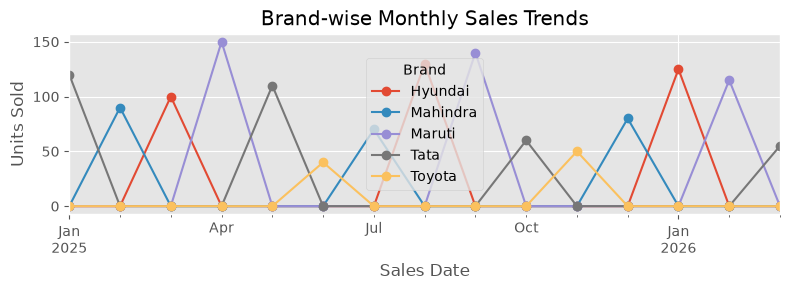

In [16]:
# 7. Expected Matplotlib Plots
# Plot 1: Multiple Line Plot – Brand-wise Sales Trends
brand_monthly = df.pivot_table(
    index='Sales_Date',
    columns='Brand',
    values='Units_Sold',
    aggfunc='sum'
).fillna(0)

brand_monthly.plot(
    kind='line',
    marker='o',
    figsize=(8, 3)
)
plt.title('Brand-wise Monthly Sales Trends')
plt.xlabel('Sales Date')
plt.ylabel('Units Sold')
plt.legend(title='Brand')
plt.grid(True)
plt.tight_layout()
plt.show()

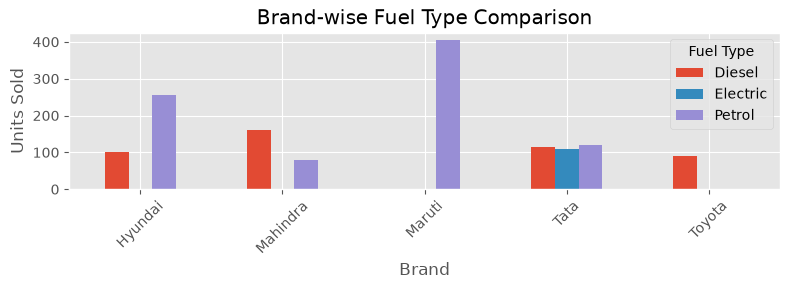

In [18]:
# Plot 2: Grouped Bar Chart – Fuel Type Comparison
fuel_comparison = df.pivot_table(
    index='Brand',
    columns='Fuel_Type',
    values='Units_Sold',
    aggfunc='sum',
    fill_value=0
)

fuel_comparison.plot(
    kind='bar',
    figsize=(8, 3)
)
plt.title('Brand-wise Fuel Type Comparison')
plt.xlabel('Brand')
plt.ylabel('Units Sold')
plt.legend(title='Fuel Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

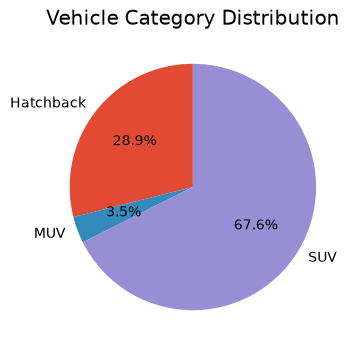

In [21]:
# Plot 3: Pie Chart – Vehicle Category Distribution
vehicle_distribution = df.groupby(
    'Vehicle_Type'
)['Units_Sold'].sum()

plt.figure(figsize=(4, 4))

plt.pie(
    vehicle_distribution,
    labels=vehicle_distribution.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Vehicle Category Distribution')
plt.show()

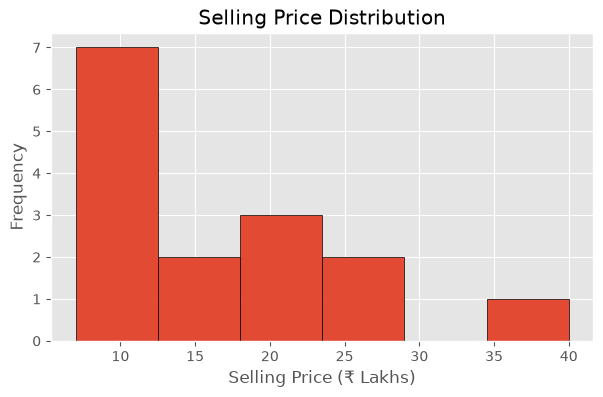

In [23]:
# Plot 4: Histogram – Selling Price Distribution
plt.figure(figsize=(7, 4))
plt.hist(
    df['Selling_Price'],
    bins=6,
    edgecolor='black'
)
plt.title('Selling Price Distribution')
plt.xlabel('Selling Price (₹ Lakhs)')
plt.ylabel('Frequency')
plt.show()

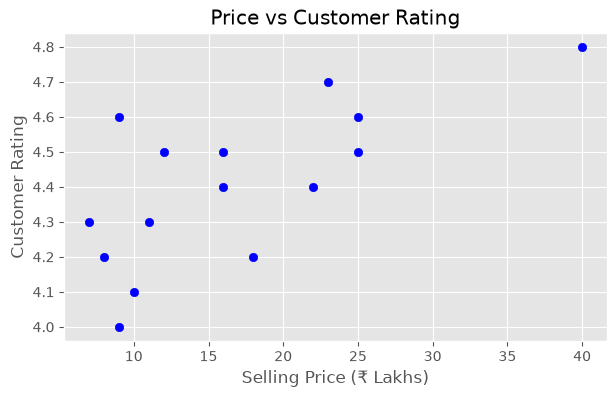

In [26]:
# Plot 5: Scatter Plot – Price vs Customer Rating
plt.figure(figsize=(7, 4))
plt.scatter(
    df['Selling_Price'],
    df['Customer_Rating'],
    color='blue'
)
plt.title('Price vs Customer Rating')
plt.xlabel('Selling Price (₹ Lakhs)')
plt.ylabel('Customer Rating')
plt.grid(True)
plt.show()

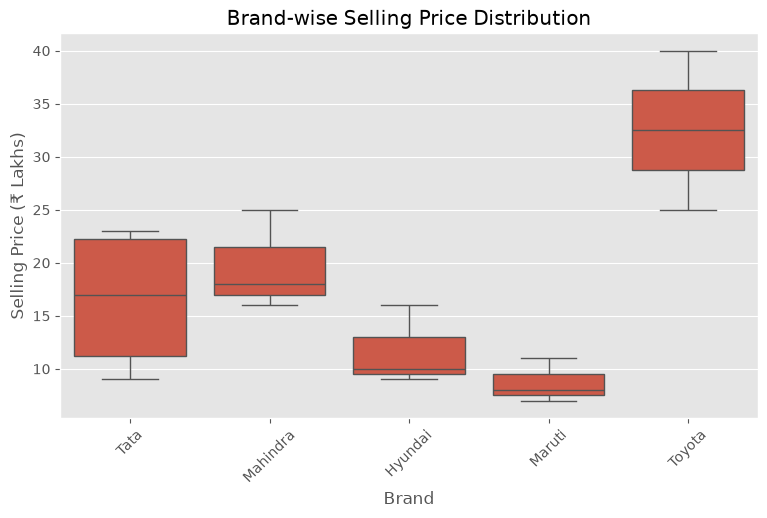

In [27]:
# Plot 6: Box Plot – Brand-wise Selling Prices
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x='Brand',
    y='Selling_Price'
)
plt.title('Brand-wise Selling Price Distribution')
plt.xlabel('Brand')
plt.ylabel('Selling Price (₹ Lakhs)')
plt.xticks(rotation=45)
plt.show()

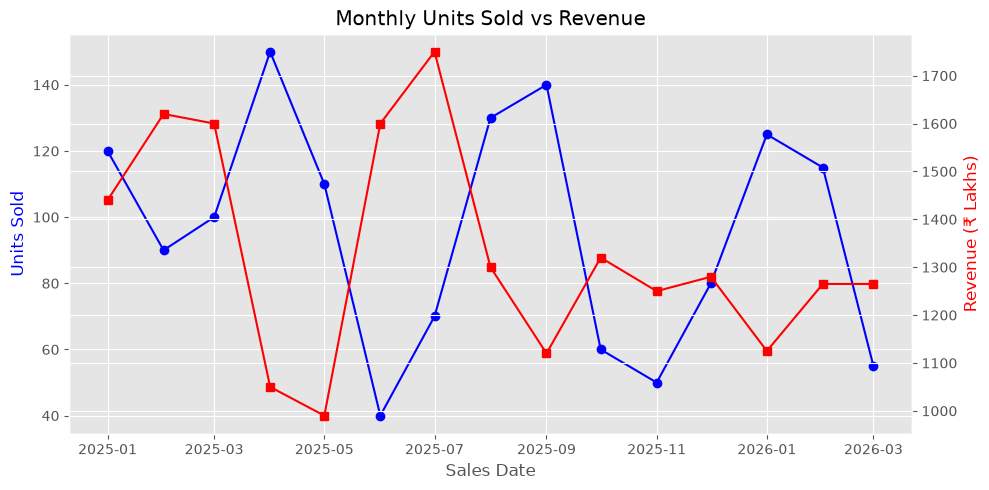

In [28]:
# Plot 7: Twin Y-axis – Units Sold vs Revenue
fig, ax1 = plt.subplots(figsize=(10, 5))

monthly = df.groupby('Sales_Date').agg({
    'Units_Sold': 'sum',
    'Revenue': 'sum'
})
ax1.plot(
    monthly.index,
    monthly['Units_Sold'],
    color='blue',
    marker='o'
)
ax1.set_xlabel('Sales Date')
ax1.set_ylabel('Units Sold', color='blue')
ax2 = ax1.twinx()
ax2.plot(
    monthly.index,
    monthly['Revenue'],
    color='red',
    marker='s'
)
ax2.set_ylabel('Revenue (₹ Lakhs)', color='red')
plt.title('Monthly Units Sold vs Revenue')
plt.tight_layout()
plt.show()

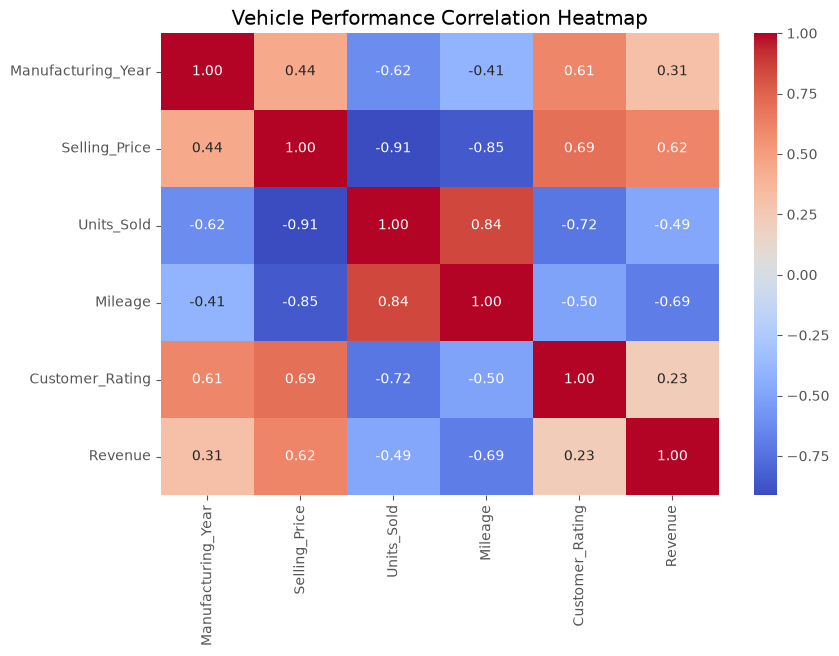

In [29]:
# Plot 8: Heatmap – Vehicle Performance Correlation
numeric_data = df[
    [
        'Manufacturing_Year',
        'Selling_Price',
        'Units_Sold',
        'Mileage',
        'Customer_Rating',
        'Revenue'
    ]
]
correlation_matrix = numeric_data.corr()
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Vehicle Performance Correlation Heatmap')
plt.show()

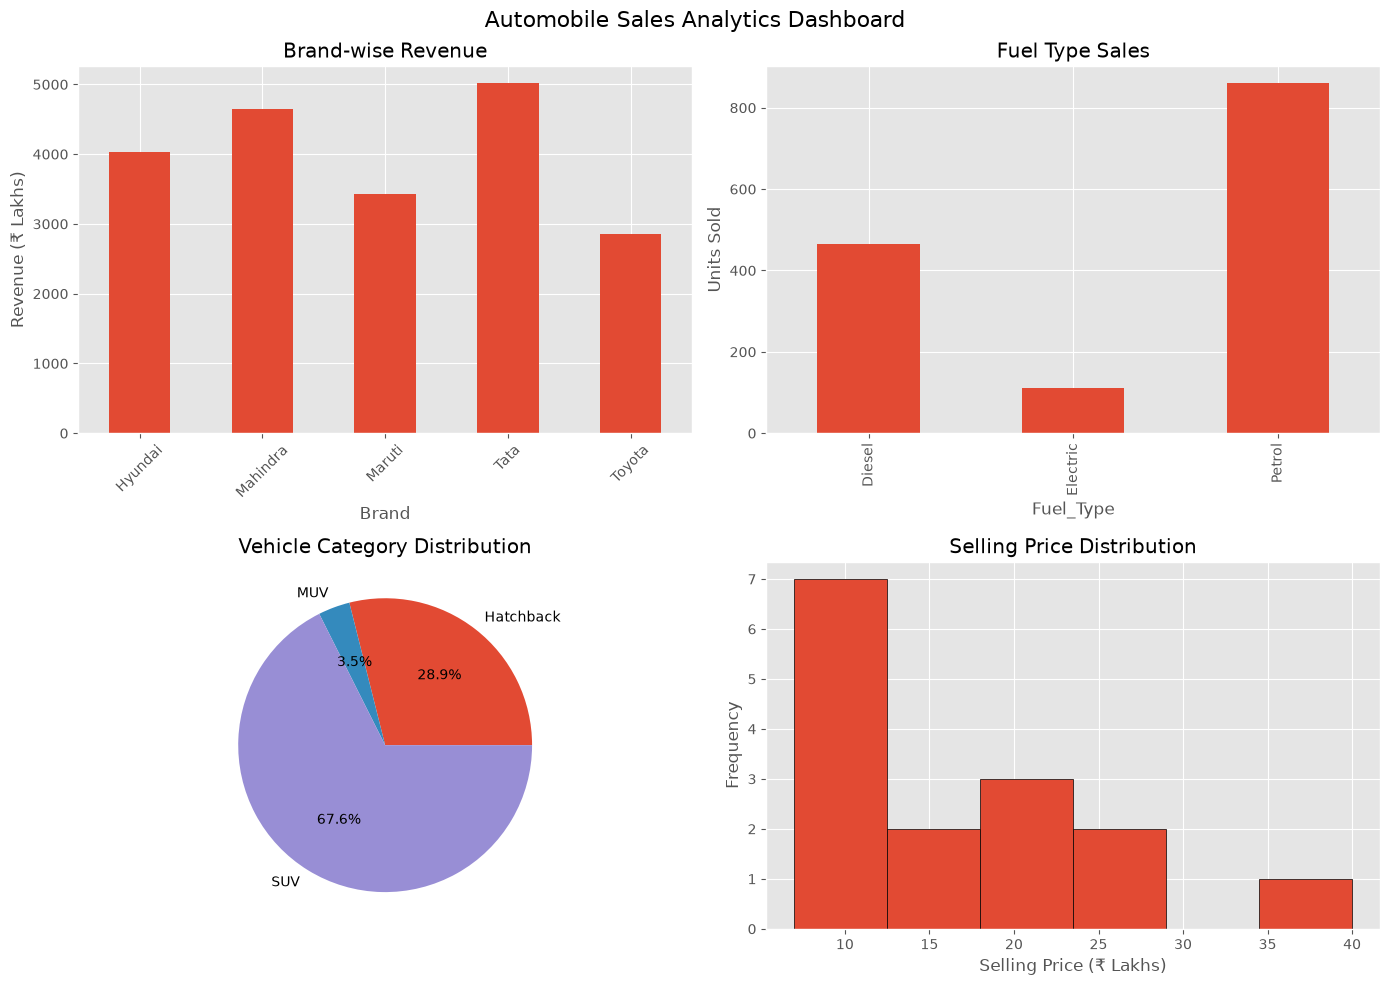

In [30]:
# 8. Automobile Analytics Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Brand Revenue
brand_revenue.plot(
    kind='bar',
    ax=axes[0, 0],
    title='Brand-wise Revenue'
)
axes[0, 0].set_ylabel('Revenue (₹ Lakhs)')
axes[0, 0].tick_params(axis='x', rotation=45)
# 2. Fuel Type Sales
fuel_sales.plot(
    kind='bar',
    ax=axes[0, 1],
    title='Fuel Type Sales'
)
axes[0, 1].set_ylabel('Units Sold')
# 3. Vehicle Type Distribution
vehicle_distribution.plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1, 0],
    title='Vehicle Category Distribution'
)
axes[1, 0].set_ylabel('')
# 4. Selling Price Histogram
axes[1, 1].hist(
    df['Selling_Price'],
    bins=6,
    edgecolor='black'
)
axes[1, 1].set_title('Selling Price Distribution')
axes[1, 1].set_xlabel('Selling Price (₹ Lakhs)')
axes[1, 1].set_ylabel('Frequency')
plt.suptitle(
    'Automobile Sales Analytics Dashboard',
    fontsize=16
)
plt.tight_layout()
plt.show()

In [31]:
# 10. Save Analysis Dataset
df.to_csv('Automobile_Analysis_Result.csv', index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
